# ขั้นที่ 3: งานที่ 2 — ป้อนพิกัด แล้วทำนายว่าจะพบซากอะไร

ทำนาย 2 ขั้น (ตามที่ตกลงกันในการถามตอบ)

| ขั้น | คำถาม | ข้อมูล train | วัดผล |
|---|---|---|---|
| **A: โอกาสพบซาก** | จุดนี้น่าจะมีแหล่งซากไหม (0–1) | แหล่ง ทธ. 518 (=1) vs background 5,000 (=0) ทำ 2 แบบ: `bg_uniform`, `bg_bias` | AUC, PR-AUC; PBDB 290 collection เป็นชุดทดสอบอิสระ (KS แบบ Block et al. 2016) |
| **B: ประเภทซาก** | ถ้ามีซาก น่าจะเป็นประเภทไหน (multi-label) | แหล่ง ทธ. ที่มี label ประเภท | macro AUC, top-1 / top-3 hit; PBDB (แปลงอนุกรมวิธานเป็นกลุ่มเดียวกัน) เป็นชุดทดสอบอิสระ |

**โมเดล**: kNN บนพิกัด (baseline เชิงพื้นที่), kNN บน feature, Random Forest, LightGBM, XGBoost, MLP (PyTorch), CNN บนภาพ Sentinel-2,
และ fusion (เฉลี่ยความน่าจะเป็นของ LightGBM กับ CNN) — ขั้น B: CNN ตั้งต้นจาก weight ของ CNN ขั้น A ใน fold เดียวกัน (transfer)

**การแบ่ง CV 3 แบบ** (fold กำหนดต่อจุดครั้งเดียว ใช้ร่วมทุกขั้นและงานที่ 1):
`random` (สุ่ม), `site_cluster` (แหล่งที่ห่างกัน < 2 กม. อยู่ fold เดียวกัน), `spatial_block` (บล็อก 50 × 50 กม.)
**ตัวเลขหลักคือ `spatial_block`** เพราะใกล้กับการป้อนพิกัดในพื้นที่ใหม่ที่สุด

**Ablation**: LightGBM กับชุด feature ต่าง ๆ — `coords` (พิกัดอย่างเดียว), `pangea`, `terrain_geo`, `s2`, `all`, `all_oc` (+หินโผล่),
`all_nolat` (ตัดละติจูดโบราณทั้งหมด), `all_nobare` (ตัด `s2_bare_frac`), `all_noexposure` (ตัดกลุ่มพื้นโล่ง: bare_frac, NDVI, BSI, ความสว่าง)

**กัน data leak / การจำพิกัด**: ทุก feature คำนวณด้วยฟังก์ชันเดียวกันทั้งแหล่งและ background, ตัดข้อมูลการถ่ายภาพ (รหัสภาพ/วันที่/เมฆ),
ตัดลองจิจูดโบราณและ **ละติจูด ณ 0 ล้านปี** (ซ้ำกับละติจูดปัจจุบัน), preprocessing fit ใน fold train เท่านั้น

**รันต่อเมื่อหยุดกลางทาง**: ทุก (การทดลอง, fold) บันทึกผล/ผลทำนาย/โมเดลไว้ใน `models/task2/` และข้ามส่วนที่เสร็จแล้ว
MLP/CNN บันทึก checkpoint ทุก epoch (`models/task2/*/ckpt/`) รันใหม่จะเทรนต่อจาก epoch ล่าสุด

In [1]:
import sys

sys.path.insert(0, ".")
import model_lib as ml          # ต้อง import ก่อน torch (ดูหมายเหตุ OpenMP ใน model_lib)
import feature_lib as fl

import json
import re

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from matplotlib import font_manager

_installed = {f.name for f in font_manager.fontManager.ttflist}
THAI_FONT = next((f for f in ["Tahoma", "Thonburi", "Noto Sans Thai", "Leelawadee UI", "Loma", "Garuda"] if f in _installed), None)
plt.rcParams.update({
    "font.family": [THAI_FONT, "DejaVu Sans"] if THAI_FONT else ["DejaVu Sans"], "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
})
pd.set_option("display.max_columns", 40, "display.width", 180)
INK, MUTED = "#52514e", "#8a8984"
ml.seed_everything(42)
OUT = ml.MODELS / "task2"
OUT.mkdir(parents=True, exist_ok=True)
PATCH_DIR = ml.FEAT / "s2" / "patches"
print("device (CNN):", ml.torch_device())

device (CNN): mps


## 1. ข้อมูล, fold และชุด feature

In [2]:
allf = pd.read_parquet(ml.FEAT / "all_features.parquet")
fg = json.loads((ml.FEAT / "feature_groups.json").read_text(encoding="utf-8"))
folds_file = ml.FEAT / "folds.parquet"
if folds_file.exists():
    folds = pd.read_parquet(folds_file)
else:
    folds = ml.assign_folds(allf[["point_id", "lon", "lat"]])
    folds.to_parquet(folds_file, index=False)
allf = allf.merge(folds, on="point_id", how="left")

CAT = ["pg_sw18_plate", "pg_me21_plate", "pg_me21_terrane", "geo_rock_sym", "geo_era_old", "geo_era_young", "geo_rock_kind", "oc_nearest_rock"]
for c in CAT:
    allf[c] = allf[c].astype(str)
# ตัด: ลองจิจูดโบราณ, ละติจูด ณ 0 ล้านปี (= ละติจูดปัจจุบัน, บอกพิกัดตรง ๆ), ข้อมูลการถ่ายภาพ Sentinel-2
DROP = re.compile(r"(_lon_\d+$|_lat_0$|_abslat_0$|_begin_ma$|_terrane$|^s2_item_id$|^s2_date$|^s2_cloud_frac$|^pg_sw18_terrane$)")
num_of = lambda prefix: [c for c in fg["groups"][prefix] if c not in CAT and not DROP.search(c)]
cat_of = lambda prefix: [c for c in CAT if c in fg["groups"][prefix]]
FS = {
    "coords": (["lon", "lat"], []),
    "pangea": (num_of("pangea"), cat_of("pangea")),
    "terrain_geo": (num_of("dem") + num_of("geology"), cat_of("geology")),
    "s2": (num_of("s2"), []),
}
FS["all"] = (FS["pangea"][0] + FS["terrain_geo"][0] + FS["s2"][0], FS["pangea"][1] + FS["terrain_geo"][1])
FS["all_oc"] = (FS["all"][0] + num_of("outcrop"), FS["all"][1] + cat_of("outcrop"))
# ตัดละติจูดโบราณทุกช่วงเวลา (เหลือแผ่นเปลือกโลก / ทะเล-บก / ความสูงโบราณ) เพื่อดูว่าโมเดลพึ่ง "ตำแหน่ง" แค่ไหน
FS["all_nolat"] = ([c for c in FS["all"][0] if not re.search(r"^pg_.*(_lat_|_abslat_|_drift_lat_)", c)], FS["all"][1])
# s2_bare_frac (สัดส่วน NDVI < 0.2) อาจเป็นผลของการขุดค้นเอง (ย้อนเหตุ-ผล): ตัดตัวเดียว และตัดทั้งกลุ่มที่บอก "พื้นโล่ง"
EXPOSURE = ["s2_bare_frac", "s2_ndvi_mean", "s2_ndvi_std", "s2_bsi_mean", "s2_brightness"]
FS["all_nobare"] = ([c for c in FS["all"][0] if c != "s2_bare_frac"], FS["all"][1])
FS["all_noexposure"] = ([c for c in FS["all"][0] if c not in EXPOSURE], FS["all"][1])
display(pd.DataFrame({k: {"numeric": len(v[0]), "categorical": len(v[1])} for k, v in FS.items()}).T)
print("fold sizes (dmr sites):", {s: allf[allf.source.eq("dmr_site")][f"fold_{s}"].value_counts().sort_index().tolist() for s in ml.CV_SCHEMES})

,numeric,categorical
coords,2,0
pangea,82,3
terrain_geo,41,4
s2,22,0
all,145,7
all_oc,149,8
all_nolat,93,7
all_nobare,144,7
all_noexposure,140,7


fold sizes (dmr sites): {'random': [122, 106, 88, 94, 108], 'site_cluster': [101, 124, 116, 91, 86], 'spatial_block': [75, 98, 128, 110, 107]}


## 2. Label ประเภทซาก (ขั้น B)

ประเภทซากมาตรฐาน (รวมคำสะกดต่าง) จาก 2 ทาง แล้วรวมกัน (แหล่งหนึ่งมีได้หลายประเภท)
1. **ตัวอย่างในทะเบียน** ที่เชื่อมกับแหล่ง (notebook 02, ความเชื่อมั่น high/medium; กรณีเสมอกันให้ทุกแหล่งที่เสมอ)
   ใช้ `f_type` ก่อน ถ้าไม่เข้ากลุ่มใดค่อยใช้ `com_name` (กันคำพ้อง เช่น "ปลากินพืช", "ลิงใบไม้")
2. **คำในชื่อและคำบรรยายแหล่ง** (`NAME_TH`, `FOS_DES_TH`) — ตัดชื่อสถานที่ที่มีคำของประเภทซากปนก่อน (`fl.NOT_FOSSIL_RE`)
   เช่น เขาประทับช้าง, ถ้ำพุงช้าง, ถ้ำค้างคาว, เขาลิงต่าง, "กวางสีคอนชา" (*Guangxiconcha* = หอยสองฝา)
   *(พบตอนตรวจทาน: รอบก่อนมี 14 จาก 25 แหล่งถูกติด "สัตว์เลี้ยงลูกด้วยนม" ผิดเพราะชื่อสถานที่)*

คำกว้าง ๆ เช่น "สัตว์ไม่มีกระดูกสันหลัง" ไม่นับเป็นประเภท | ประเภทที่มีน้อยกว่า 10 แหล่งจะไม่ใช้ในโมเดล (วัดผลไม่ได้)

In [3]:
# กลุ่มประเภทซาก + คำสะกดต่าง อยู่ใน feature_lib (ใช้ร่วมกับ notebook 11, 12)
CLASSES = fl.FOSSIL_CLASSES
classes_of = fl.classes_of
for c, kws in CLASSES.items():
    print(f"{c:22s} <- {', '.join(kws)}")

spec = pd.read_csv(ml.DATA / "processed" / "fossil_list_final.csv", dtype={"fossil_id": str, "site_OBJECTID": "Int64"},
                   encoding="utf-8-sig", low_memory=False)
hm = spec[spec.confidence.isin(["high", "medium"])].copy()
hm["cls"] = [fl.specimen_classes(t, c) for t, c in zip(hm.f_type, hm.com_name)]
hm["sid"] = hm.tied_site_ids.str.split(";")
hm = hm.explode("sid")
from_spec = hm.groupby(hm.sid.astype(float).astype(int)).cls.agg(lambda s: set().union(*s))

raw = gpd.read_file(ml.DATA / "dmr_fossil_sites" / "fossil_sites.geojson")[["OBJECTID", "NAME_TH", "FOS_DES_TH"]]
raw["OBJECTID"] = raw.OBJECTID.astype(int)
from_text = pd.Series({o: classes_of(f"{n or ''} {d or ''}") for o, n, d in zip(raw.OBJECTID, raw.NAME_TH, raw.FOS_DES_TH)})

site_lab = {o: from_spec.get(o, set()) | from_text.get(o, set()) for o in raw.OBJECTID}
both = [o for o in raw.OBJECTID if from_spec.get(o) and from_text.get(o)]
print(f"แหล่งที่มี label: {sum(bool(v) for v in site_lab.values())} / {len(site_lab)} "
      f"(จากตัวอย่าง {sum(bool(from_spec.get(o)) for o in raw.OBJECTID)}, จากคำในชื่อ {sum(bool(from_text.get(o)) for o in raw.OBJECTID)}) | "
      f"สองทางตรงกันอย่างน้อย 1 ประเภท {np.mean([bool(from_spec[o] & from_text[o]) for o in both]):.0%} ของ {len(both)} แหล่ง")
counts = pd.Series([c for v in site_lab.values() for c in v]).value_counts().reindex(list(CLASSES)).fillna(0).astype(int)
MIN_SITES = 10                     # ลดจาก 15 หลังแก้ label (สัตว์เลี้ยงลูกด้วยนมเหลือ 11 แหล่ง)
KEEP = [c for c in CLASSES if counts[c] >= MIN_SITES]
print("ใช้ในโมเดล:", KEEP)
print(f"ตัดออก (< {MIN_SITES} แหล่ง):", {c: int(counts[c]) for c in CLASSES if c not in KEEP})
counts.rename("แหล่ง").to_frame().T

ไดโนเสาร์              <- ไดโนเสาร์, ซอโรพอด, เทอโรพอด, ออร์นิโทพอด, สเตโกซอรัส, ซิตตะโกซอรัส
สัตว์เลื้อยคลานอื่น    <- จระเข้, เต่า, ไฟโตซอร์, กิ้งก่า, ตะกวด, เหี้ย, สัตว์เลื้อยคลาน
ปลา                    <- ปลา, ฉลาม
สัตว์เลี้ยงลูกด้วยนม   <- สัตว์กีบคู่, สัตว์กีบคี่, สัตว์งวง, สัตว์เลี้ยงลูกด้วยนม, ไพรเมต, สัตว์กินเนื้อ, ช้าง, แรด, วาฬ, ลิง, กวาง, ไฮยีนา, สัตว์ฟันแทะ, ค้างคาว, หมู, วัว, สมเสร็จ
แบรคิโอพอด             <- แบรคิโอพอด, บราคิโอพอด
หอยสองฝา               <- หอยกาบคู่, หอยสองฝา
หอยฝาเดียว             <- หอยกาบเดี่ยว, หอยฝาเดียว, หอยขม, หอยโข่ง
เซฟาโลพอด              <- เซฟาโลพอด, แอมโมไนต์, แอมโมนอยด์, นอติลอยด์
ปะการัง                <- ปะการัง, ประการัง, แอนโธซัว, เทบูเลต
ไครนอยด์               <- ไครนอยด์, ไคร์นอยด์, พลับพลึงทะเล, เอไคโนเดิร์ม
ไบรโอซัว               <- ไบรโอซัว
ไทรโลไบต์              <- ไทรโลไบต์
แกรปโตไลต์             <- แกรปโตไลต์
ฟอแรม/ฟิวซูลินิด       <- ฟิวซูลินิด, ฟอแรม, คตข้าวสาร
เรดิโอลาเรีย           <- เรดิโอลาเรีย
พืช                    <- พื

แหล่งที่มี label: 498 / 518 (จากตัวอย่าง 242, จากคำในชื่อ 491) | สองทางตรงกันอย่างน้อย 1 ประเภท 88% ของ 235 แหล่ง
ใช้ในโมเดล: ['ไดโนเสาร์', 'สัตว์เลื้อยคลานอื่น', 'ปลา', 'สัตว์เลี้ยงลูกด้วยนม', 'แบรคิโอพอด', 'หอยสองฝา', 'หอยฝาเดียว', 'เซฟาโลพอด', 'ปะการัง', 'ไครนอยด์', 'ไบรโอซัว', 'ไทรโลไบต์', 'แกรปโตไลต์', 'ฟอแรม/ฟิวซูลินิด', 'พืช', 'ร่องรอย']
ตัดออก (< 10 แหล่ง): {'เรดิโอลาเรีย': 9}


,ไดโนเสาร์,สัตว์เลื้อยคลานอื่น,ปลา,สัตว์เลี้ยงลูกด้วยนม,แบรคิโอพอด,หอยสองฝา,หอยฝาเดียว,เซฟาโลพอด,ปะการัง,ไครนอยด์,ไบรโอซัว,ไทรโลไบต์,แกรปโตไลต์,ฟอแรม/ฟิวซูลินิด,เรดิโอลาเรีย,พืช,ร่องรอย
แหล่ง,81,61,51,11,178,119,99,82,135,141,57,44,12,79,9,66,54


In [4]:
# PBDB -> กลุ่มเดียวกัน (phylum / class / order) ด้วย fl.pbdb_class
occ = pd.read_csv(ml.DATA / "pbdb_thailand" / "occurrences.csv", low_memory=False)


occ["cls"] = [fl.pbdb_class(a, b, c) for a, b, c in zip(occ.phylum, occ["class"], occ.order)]
pb_lab = occ.dropna(subset=["cls"]).groupby(occ.collection_no.astype(str)).cls.agg(set)
pb_points = allf[allf.source.eq("pbdb")]
pb_lab = {pid: pb_lab.get(pid[5:], set()) for pid in pb_points.point_id}
print(f"PBDB collection ที่ได้ label ในกลุ่มที่ใช้: {sum(bool(v & set(KEEP)) for v in pb_lab.values())} / {len(pb_lab)}")
pd.Series([c for v in pb_lab.values() for c in v if c in KEEP]).value_counts().rename("collection").to_frame().T

PBDB collection ที่ได้ label ในกลุ่มที่ใช้: 249 / 290


,สัตว์เลื้อยคลานอื่น,ปะการัง,ไดโนเสาร์,แบรคิโอพอด,ปลา,ฟอแรม/ฟิวซูลินิด,สัตว์เลี้ยงลูกด้วยนม,เซฟาโลพอด,ไบรโอซัว,หอยสองฝา,หอยฝาเดียว,พืช,ไครนอยด์,ไทรโลไบต์,แกรปโตไลต์
collection,69,41,40,39,35,31,27,24,22,16,14,12,10,4,1


## 3. ขั้น A: โอกาสพบซาก

รันทุก (background × CV × โมเดล) และ ablation ชุด feature ด้วย LightGBM — ผลเก็บใน `models/task2/A_<bg>/`

In [5]:
patches_all, has_patch = ml.load_patches(allf.point_id.values, PATCH_DIR)
print(f"มี patch Sentinel-2: {has_patch.mean():.1%} ของ {len(allf):,} จุด")
PIDX = dict(zip(allf.point_id, range(len(allf))))

A_MODELS = ["knn_coords", "knn", "rf", "lgbm", "xgb", "mlp", "cnn"]
A_ABL = [k for k in FS if k != "all"]
regA = {}


def run_stage_a(bg):
    reg = regA.setdefault(bg, ml.Registry(OUT / f"A_{bg}"))
    d = allf[allf.source.isin(["dmr_site", bg])].reset_index(drop=True)
    y = d.source.eq("dmr_site").astype(int).values
    P = patches_all[[PIDX[p] for p in d.point_id]]
    jobs = [(cv, m) for cv in ml.CV_SCHEMES for m in A_MODELS] + [(cv, f"lgbm@{fs}") for cv in ml.CV_SCHEMES for fs in A_ABL]
    for cv, m in ml.tqdm_auto()(jobs, desc=f"ขั้น A {bg}"):
        exp, fc = f"{cv}__{m}", f"fold_{cv}"
        if m == "knn_coords":
            ml.run_tabular_cv(reg, exp, d, y, fc, "knn", ["lon", "lat"], [])
        elif m == "mlp":
            ml.run_torch_cv(reg, exp, d, y, fc, "mlp", num_cols=FS["all"][0], cat_cols=FS["all"][1], epochs=60)
        elif m == "cnn":
            ml.run_torch_cv(reg, exp, d, y, fc, "cnn", patches=P, epochs=40)
        elif "@" in m:
            ml.run_tabular_cv(reg, exp, d, y, fc, "lgbm", *FS[m.split("@")[1]])
        else:
            ml.run_tabular_cv(reg, exp, d, y, fc, m, *FS["all"])
    for cv in ml.CV_SCHEMES:
        ml.run_fusion(reg, f"{cv}__fusion", [f"{cv}__lgbm", f"{cv}__cnn"])
    return reg.results()


resA_bias = run_stage_a("bg_bias")

มี patch Sentinel-2: 100.0% ของ 10,808 จุด


spatial_block__lgbm@all_noexposure:   0%|          | 0/5 [00:00<?, ?it/s]


In [6]:
resA_uni = run_stage_a("bg_uniform")

spatial_block__lgbm@all_noexposure:   0%|          | 0/5 [00:00<?, ?it/s]


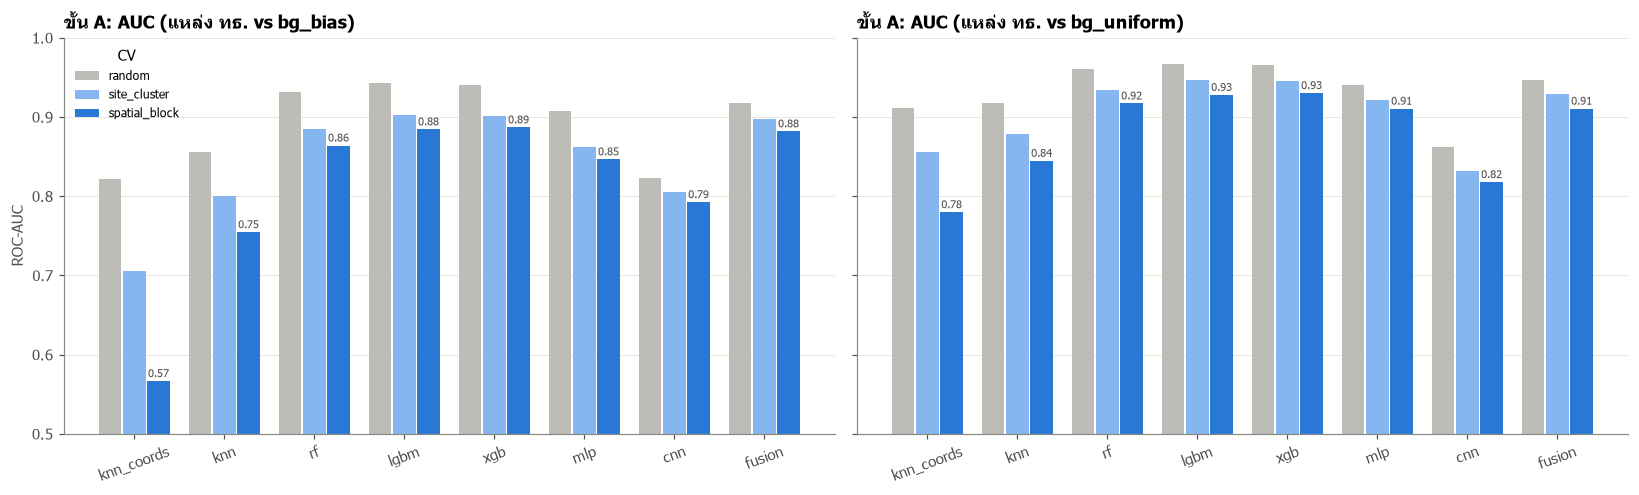

In [7]:
def table(res, metric):
    r = res.copy()
    r[["cv", "model"]] = r.exp.str.split("__", expand=True)
    return r.groupby(["model", "cv"])[metric].mean().unstack("cv")[ml.CV_SCHEMES]


A_ORDER = ["knn_coords", "knn", "rf", "lgbm", "xgb", "mlp", "cnn", "fusion"]
tA = pd.concat({bg: table(regA[bg].results(), "auc").reindex(A_ORDER + [f"lgbm@{f}" for f in A_ABL]) for bg in regA}, axis=1)
display(tA.style.format("{:.3f}").background_gradient(cmap="Blues", axis=None))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), sharey=True)
cv_color = {"random": "#bdbcb6", "site_cluster": "#86b6ef", "spatial_block": "#2a78d6"}
for ax, bg in zip(axes, ["bg_bias", "bg_uniform"]):
    t = table(regA[bg].results(), "auc").reindex(A_ORDER)
    x = np.arange(len(t))
    for i, cv in enumerate(ml.CV_SCHEMES):
        ax.bar(x + (i - 1) * 0.27, t[cv], width=0.25, color=cv_color[cv], label=cv)
    for xi, v in zip(x, t["spatial_block"]):
        ax.text(xi + 0.27, v + 0.005, f"{v:.2f}", ha="center", fontsize=7, color=INK)
    ax.set_xticks(x, t.index, rotation=20)
    ax.set_ylim(0.5, 1.0)
    ax.set_title(f"ขั้น A: AUC (แหล่ง ทธ. vs {bg})")
    ax.grid(axis="x", visible=False)
axes[0].legend(frameon=False, fontsize=8, title="CV")
axes[0].set_ylabel("ROC-AUC")
plt.tight_layout()

### ตรวจกับ PBDB (ชุดอิสระ, ไม่เคยใช้ train)

ให้โมเดลทั้ง 5 fold (`spatial_block`) ทำนาย PBDB 290 collection แล้วเฉลี่ย เทียบกับคะแนนของจุดสุ่ม `bg_uniform`
(โมเดลที่ train กับ `bg_uniform`: ใช้ผลทำนาย out-of-fold ของจุดสุ่ม; โมเดลที่ train กับ `bg_bias`: จุดสุ่มไม่เคยถูกใช้ train อยู่แล้ว)
- **AUC (PBDB vs สุ่ม)** และ **KS statistic** (Block et al. 2016: 0 = เหมือนจุดสุ่ม, 1 = แยกได้หมด)

In [8]:
pb = allf[allf.source.eq("pbdb")].reset_index(drop=True)
pbP = patches_all[[PIDX[p] for p in pb.point_id]]
bu = allf[allf.source.eq("bg_uniform")].reset_index(drop=True)
buP = patches_all[[PIDX[p] for p in bu.point_id]]


def random_scores(reg, bg, exp, m):
    if bg == "bg_uniform":                      # out-of-fold ของจุดสุ่ม (เรียงตาม bu)
        o = reg.oof(exp).set_index("point_id").p
        return o.reindex(bu.point_id).values
    return ml.predict_with_fold_models(reg, exp, buP if m == "cnn" else bu)


rows = []
for bg in regA:
    s_pb, s_rnd = {}, {}
    for m in ["knn_coords", "rf", "lgbm", "xgb", "mlp", "cnn"]:
        exp = f"spatial_block__{m}"
        s_pb[m] = ml.predict_with_fold_models(regA[bg], exp, pbP if m == "cnn" else pb)
        s_rnd[m] = random_scores(regA[bg], bg, exp, m)
    s_pb["fusion"], s_rnd["fusion"] = (s_pb["lgbm"] + s_pb["cnn"]) / 2, (s_rnd["lgbm"] + s_rnd["cnn"]) / 2
    for m in s_pb:
        y = np.r_[np.ones(len(s_pb[m])), np.zeros(len(s_rnd[m]))]
        rows.append({"background": bg, "model": m, "AUC_pbdb_vs_random": ml.roc_auc_score(y, np.r_[s_pb[m], s_rnd[m]]),
                     "KS": ml.ks_vs_random(s_pb[m], s_rnd[m])})
pbdbA = pd.DataFrame(rows)
pbdbA.pivot(index="model", columns="background", values=["AUC_pbdb_vs_random", "KS"]).reindex(A_ORDER).round(3)

AUC_pbdb_vs_random                 KS           
background            bg_bias bg_uniform bg_bias bg_uniform
model                                                      
knn_coords              0.773      0.792   0.448      0.466
knn                       NaN        NaN     NaN        NaN
rf                      0.779      0.783   0.439      0.471
lgbm                    0.796      0.821   0.465      0.517
xgb                     0.797      0.815   0.458      0.513
mlp                     0.773      0.808   0.436      0.467
cnn                     0.671      0.693   0.296      0.319
fusion                  0.729      0.754   0.349      0.389

## 4. ขั้น B: ประเภทซาก (multi-label)

train บนแหล่ง ทธ. ที่มี label | CNN ตั้งต้นจาก backbone ของ CNN ขั้น A (`bg_bias`) ที่ใช้ CV แบบเดียวกันและ fold เดียวกัน
(backbone นั้นไม่เคยเห็นแหล่งใน fold ทดสอบ จึงไม่รั่วข้อมูล)

In [9]:
sites = allf[allf.source.eq("dmr_site")].copy()
sites["oid"] = sites.point_id.str[4:].astype(int)
sites["labels"] = sites.oid.map(site_lab)
dB = sites[sites.labels.map(lambda s: bool(s & set(KEEP)))].reset_index(drop=True)
YB = np.array([[int(c in s) for c in KEEP] for s in dB.labels])
PB = patches_all[[PIDX[p] for p in dB.point_id]]
print(f"แหล่งที่ใช้ train ขั้น B: {len(dB)} | label เฉลี่ย {YB.sum(axis=1).mean():.2f} ประเภทต่อแหล่ง")

regB = ml.Registry(OUT / "B_v3")         # label หลังตรวจทาน (ชื่อสถานที่ 16 คำ) + เกณฑ์ 10 แหล่ง (B/ = รอบแรก, B_v2 = ก่อนเจอ ภูเต่า/เขาปลาร้า)
B_MODELS = ["prior", "knn_coords", "rf", "lgbm", "xgb", "mlp", "cnn"]
kw = dict(task="multilabel", classes=KEEP)
jobs = [(cv, m) for cv in ml.CV_SCHEMES for m in B_MODELS] + [(cv, f"lgbm@{fs}") for cv in ml.CV_SCHEMES for fs in A_ABL]
for cv, m in ml.tqdm_auto()(jobs, desc="ขั้น B"):
    exp, fc = f"{cv}__{m}", f"fold_{cv}"
    if m == "knn_coords":
        ml.run_tabular_cv(regB, exp, dB, YB, fc, "knn", ["lon", "lat"], [], **kw)
    elif m == "prior":
        ml.run_tabular_cv(regB, exp, dB, YB, fc, "prior", ["lon"], [], **kw)
    elif m == "mlp":
        ml.run_torch_cv(regB, exp, dB, YB, fc, "mlp", num_cols=FS["all"][0], cat_cols=FS["all"][1], epochs=80, **kw)
    elif m == "cnn":
        src = lambda k, cv=cv: regA["bg_bias"].model_path(f"{cv}__cnn", k, "pt")
        ml.run_torch_cv(regB, exp, dB, YB, fc, "cnn", patches=PB, epochs=40, lr=5e-4, init_from=src, **kw)
    elif "@" in m:
        ml.run_tabular_cv(regB, exp, dB, YB, fc, "lgbm", *FS[m.split("@")[1]], **kw)
    else:
        ml.run_tabular_cv(regB, exp, dB, YB, fc, m, *FS["all"], **kw)
for cv in ml.CV_SCHEMES:
    ml.run_fusion(regB, f"{cv}__fusion", [f"{cv}__lgbm", f"{cv}__cnn"], task="multilabel")

แหล่งที่ใช้ train ขั้น B: 490 | label เฉลี่ย 2.59 ประเภทต่อแหล่ง


spatial_block__lgbm@all_noexposure:   0%|          | 0/5 [00:00<?, ?it/s]


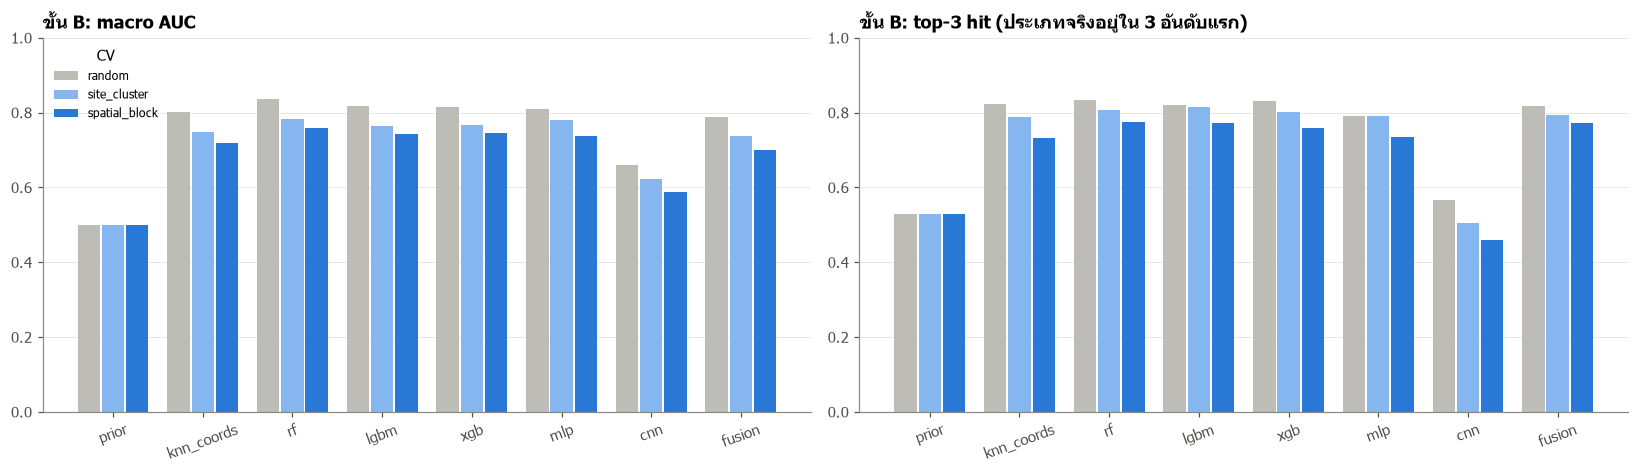

In [10]:
B_ORDER = ["prior", "knn_coords", "rf", "lgbm", "xgb", "mlp", "cnn", "fusion"]
tB = pd.concat({m: table(regB.results(), m).reindex(B_ORDER + [f"lgbm@{f}" for f in A_ABL]) for m in ["macro_auc", "top3"]}, axis=1)
display(tB.style.format("{:.3f}").background_gradient(cmap="Blues", axis=None))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.4))
for ax, metric, title in [(axes[0], "macro_auc", "macro AUC"), (axes[1], "top3", "top-3 hit (ประเภทจริงอยู่ใน 3 อันดับแรก)")]:
    t = table(regB.results(), metric).reindex(B_ORDER)
    x = np.arange(len(t))
    for i, cv in enumerate(ml.CV_SCHEMES):
        ax.bar(x + (i - 1) * 0.27, t[cv], width=0.25, color=cv_color[cv], label=cv)
    ax.set_xticks(x, t.index, rotation=20)
    ax.set_ylim(0, 1)
    ax.set_title(f"ขั้น B: {title}")
    ax.grid(axis="x", visible=False)
axes[0].legend(frameon=False, fontsize=8, title="CV")
plt.tight_layout()

In [11]:
# ความแม่นรายประเภท (spatial_block) ของโมเดลตารางที่ใช้จริง (RF; ไม่เฉลี่ยกับ CNN ตาม deploy) และทดสอบกับ PBDB
oofB = regB.oof("spatial_block__rf")
per_class = pd.DataFrame({c: {"แหล่ง": int(oofB[f"y_{j}"].sum()),
                              "AUC": ml.roc_auc_score(oofB[f"y_{j}"], oofB[f"p_{j}"]) if 0 < oofB[f"y_{j}"].sum() < len(oofB) else np.nan}
                          for j, c in enumerate(KEEP)}).T.sort_values("AUC", ascending=False)
display(per_class.style.format({"AUC": "{:.3f}", "แหล่ง": "{:.0f}"}))

pbB = pb[[bool(pb_lab[p] & set(KEEP)) for p in pb.point_id]].reset_index(drop=True)
YpbB = np.array([[int(c in pb_lab[p]) for c in KEEP] for p in pbB.point_id])
pbBP = patches_all[[PIDX[p] for p in pbB.point_id]]
rows = []
for m in ["prior", "knn_coords", "rf", "lgbm", "xgb", "mlp", "cnn"]:
    P_ = ml.predict_with_fold_models(regB, f"spatial_block__{m}", pbBP if m == "cnn" else pbB)
    if m == "lgbm":
        P_lgbm = P_
    if m == "cnn":
        P_cnn = P_
    rows.append({"model": m, **ml.multilabel_metrics(YpbB, P_, min_pos=5)})
rows.append({"model": "fusion", **ml.multilabel_metrics(YpbB, (P_lgbm + P_cnn) / 2, min_pos=5)})
pbdbB = pd.DataFrame(rows).set_index("model")
print(f"PBDB ที่มี label ในกลุ่มที่ใช้: {len(pbB)} collection")
pbdbB.round(3)

,แหล่ง,AUC
แกรปโตไลต์,12,0.951
ไดโนเสาร์,81,0.950
ปลา,51,0.891
สัตว์เลื้อยคลานอื่น,61,0.888
สัตว์เลี้ยงลูกด้วยนม,11,0.878
ไทรโลไบต์,44,0.861
ฟอแรม/ฟิวซูลินิด,79,0.826
แบรคิโอพอด,178,0.763
เซฟาโลพอด,82,0.757
ไครนอยด์,141,0.743


PBDB ที่มี label ในกลุ่มที่ใช้: 249 collection


,macro_auc,top1,top3,n_classes_eval
model,,,,
prior,0.500,0.157,0.313,13
knn_coords,0.732,0.309,0.631,13
rf,0.776,0.345,0.651,13
lgbm,0.757,0.329,0.606,13
xgb,0.762,0.349,0.598,13
mlp,0.772,0.301,0.590,13
cnn,0.551,0.124,0.317,13
fusion,0.703,0.317,0.598,13


### 4b. ทดลอง: label ประเภทซากจากตัวอย่างที่เชื่อมแบบเข้มงวด (ยังไม่เปลี่ยนโมเดลตัวจริง)

label ปัจจุบัน = คำในชื่อ/คำบรรยายแหล่ง ∪ ตัวอย่างในทะเบียนที่เชื่อมแหล่งด้วยความเชื่อมั่น high/medium (ทุกระดับการเชื่อม)
— ตรวจพบคู่ "แหล่ง–ประเภท" ที่มาจากตัวอย่างอย่างเดียวจำนวนหนึ่ง บางคู่ผิดชัด (เช่น ลิง *Macaca* ติดแหล่งแบรคิโอพอดโรงเรียนเมืองกระบี่
เพราะเชื่อมได้แค่ระดับตำบล) จึงเทียบ 3 แบบ (RF, feature และคลาส `KEEP` เดียวกัน, CV `spatial_block`):
- **ปัจจุบัน** | **เข้มงวด**: ตัวอย่างต้องเชื่อมระดับตำแหน่ง/ตำบล และความเชื่อมั่น high | **คำในชื่อเท่านั้น**: ไม่ใช้ตัวอย่าง

วัด 3 ทาง: (1) label ของตัวเอง (ต่างชุดกัน เทียบตรง ๆ ไม่ได้) (2) label กลาง = คำในชื่อแหล่ง (เอียงเข้าข้างแบบ "คำในชื่อเท่านั้น")
(3) **PBDB** (ชุดอิสระ ไม่ขึ้นกับการเชื่อมตัวอย่าง → ใช้ตัดสินเป็นหลัก)

In [12]:
strict = hm[hm.confidence.eq("high") & hm.match_level.isin(["locality", "tambon"])]
from_spec_strict = strict.groupby(strict.sid.astype(float).astype(int)).cls.agg(lambda s: set().union(*s))
LAB_VARIANTS = {"ปัจจุบัน": site_lab,
                "เข้มงวด": {o: from_spec_strict.get(o, set()) | from_text.get(o, set()) for o in raw.OBJECTID},
                "คำในชื่อเท่านั้น": {o: from_text.get(o, set()) for o in raw.OBJECTID}}
REG_LAB = {"ปัจจุบัน": regB, "เข้มงวด": ml.Registry(OUT / "B_v3_labels" / "strict"), "คำในชื่อเท่านั้น": ml.Registry(OUT / "B_v3_labels" / "text_only")}
text_sites = {o for o, v in from_text.items() if v & set(KEEP)}
rows, PB_LAB = [], {}
for name, lab_ in LAB_VARIANTS.items():
    s_ = sites.assign(labels=sites.oid.map(lab_))
    d_ = s_[s_.labels.map(lambda v: bool(v & set(KEEP)))].reset_index(drop=True)
    Y_ = np.array([[int(c in v) for c in KEEP] for v in d_.labels])
    reg_ = REG_LAB[name]
    ml.run_tabular_cv(reg_, "spatial_block__rf", d_, Y_, "fold_spatial_block", "rf", *FS["all"], task="multilabel", classes=KEEP)
    own = reg_.results().query("exp == 'spatial_block__rf'")[["macro_auc", "top3"]].mean()
    o = reg_.oof("spatial_block__rf").set_index("point_id")
    o = o[o.index.str[4:].astype(int).isin(text_sites)]
    Yt = np.array([[int(c in from_text[int(p[4:])]) for c in KEEP] for p in o.index])
    ref = pd.DataFrame([ml.multilabel_metrics(Yt[o.fold.values == k], o.loc[o.fold == k, [f"p_{j}" for j in range(len(KEEP))]].values)
                        for k in sorted(o.fold.unique())])[["macro_auc", "top3"]].mean()
    P_ = PB_LAB[name] = ml.predict_with_fold_models(reg_, "spatial_block__rf", pbB)
    pbm = ml.multilabel_metrics(YpbB, P_, min_pos=5)
    rows.append({"label": name, "แหล่ง": len(d_), "ประเภท/แหล่ง": Y_.sum(1).mean(),
                 "(1) macro AUC": own.macro_auc, "(1) top-3": own.top3, "(2) macro AUC": ref.macro_auc, "(2) top-3": ref.top3,
                 "(3) PBDB macro AUC": pbm["macro_auc"], "(3) PBDB top-3": pbm["top3"]})
tLab = pd.DataFrame(rows).set_index("label")
display(tLab.style.format({c: "{:.3f}" for c in tLab.columns if c != "แหล่ง"}))

# ส่วนต่างบน PBDB เทียบ label ปัจจุบัน: bootstrap collection 1,000 รอบ (ช่วง 95%)
rng = np.random.default_rng(0)
boot = {k: {"auc": [], "top3": []} for k in ["เข้มงวด", "คำในชื่อเท่านั้น"]}
for _ in ml.tqdm_auto()(range(1000), desc="bootstrap PBDB"):
    i = rng.integers(0, len(YpbB), len(YpbB))
    base_ = ml.multilabel_metrics(YpbB[i], PB_LAB["ปัจจุบัน"][i], min_pos=5)
    for k in boot:
        m_ = ml.multilabel_metrics(YpbB[i], PB_LAB[k][i], min_pos=5)
        boot[k]["auc"].append(m_["macro_auc"] - base_["macro_auc"]), boot[k]["top3"].append(m_["top3"] - base_["top3"])
for k, v in boot.items():
    print(f"{k} − ปัจจุบัน (PBDB {len(YpbB)} collection): macro AUC {np.mean(v['auc']):+.3f} [{np.percentile(v['auc'], 2.5):+.3f}, {np.percentile(v['auc'], 97.5):+.3f}] | "
          f"top-3 {np.mean(v['top3']):+.3f} [{np.percentile(v['top3'], 2.5):+.3f}, {np.percentile(v['top3'], 97.5):+.3f}]")

spatial_block__rf:   0%|          | 0/5 [00:00<?, ?it/s]


,แหล่ง,ประเภท/แหล่ง,(1) macro AUC,(1) top-3,(2) macro AUC,(2) top-3,(3) PBDB macro AUC,(3) PBDB top-3
label,,,,,,,,
ปัจจุบัน,490,2.592,0.758,0.776,0.756,0.735,0.776,0.651
เข้มงวด,486,2.325,0.759,0.743,0.756,0.730,0.787,0.635
คำในชื่อเท่านั้น,483,2.240,0.758,0.738,0.758,0.738,0.791,0.639


bootstrap PBDB: 100%|██████████| 1000/1000 [00:45<00:00, 22.19it/s]


เข้มงวด − ปัจจุบัน (PBDB 249 collection): macro AUC +0.009 [-0.002, +0.020] | top-3 -0.016 [-0.048, +0.012]
คำในชื่อเท่านั้น − ปัจจุบัน (PBDB 249 collection): macro AUC +0.011 [-0.004, +0.024] | top-3 -0.012 [-0.040, +0.016]


## 5. โมเดลตัวจริง (train ด้วยข้อมูลทั้งหมด) และบันทึก

เลือก**โมเดลตารางที่ดีที่สุดตาม `spatial_block`** (จาก RF / LightGBM / XGBoost / MLP) + CNN แล้ว train ใหม่ด้วยข้อมูลทั้งหมด
- ขั้น A: ทำทั้ง `bg_bias` และ `bg_uniform` — **ใช้ทั้งสองแบบ** ในแผนที่/inference (`bg_bias` เป็นค่าเริ่มต้น)
- **ใช้โมเดลตารางอย่างเดียว** (`deploy.use_cnn = false`): เฉลี่ยกับ CNN ทำให้ AUC ลดลงทั้ง CV และ PBDB — CNN ตัวจริงยังบันทึกไว้ใช้เป็น embedding ในงานที่ 1
- ขั้น B: CNN ตั้งต้นจาก CNN ขั้น A ตัวจริง (`bg_bias`)
- บันทึกที่ `models/task2/final/` พร้อม `final_meta.json` (รายชื่อ feature, คลาส, คะแนน CV) — MLP/CNN มี checkpoint ระหว่าง train

In [13]:
FINAL = OUT / "final"
FINAL.mkdir(exist_ok=True)


def best_tabular(res, metric):
    t = table(res, metric)["spatial_block"]
    return t.reindex(["rf", "lgbm", "xgb", "mlp"]).idxmax()


meta = {"classes_B": KEEP, "features": {"num": FS["all"][0], "cat": FS["all"][1]}, "cv_main": "spatial_block", "stage_A": {}, "stage_B": {},
        # ตกลงกันหลังดูผล: ใช้ทั้งสอง background และโมเดลตารางอย่างเดียว (เฉลี่ยกับ CNN ทำให้แย่ลงทั้ง CV และ PBDB)
        "deploy": {"backgrounds": ["bg_bias", "bg_uniform"], "default_background": "bg_bias", "use_cnn": False,
                   # notebook 14: ลองขั้น A แบบ XGBoost + ธรณี+ / ผิวดิน / บริบทเชิงพื้นที่ ("fe", final_meta_fe.json) — CV ดีขึ้นเล็กน้อย
                   # แต่ทดสอบ PBDB กับทั้งประเทศแย่ลง (bg_bias AUC −0.012, 95% CI −0.024…−0.002) จึงตกลงกลับมาใช้ "base"
                   "stage_A_variant": "base"}}
for bg in ["bg_bias", "bg_uniform"]:
    d = allf[allf.source.isin(["dmr_site", bg])].reset_index(drop=True)
    y = d.source.eq("dmr_site").astype(int).values
    tab = best_tabular(regA[bg].results(), "auc")
    tab_path = FINAL / f"A_{bg}_{tab}.{'pt' if tab == 'mlp' else 'joblib'}"
    # fit_final_* ใช้ไฟล์เดิมเฉพาะเมื่อ fingerprint (ข้อมูล / feature / ค่าตั้ง) ตรงกับปัจจุบัน ไม่งั้น train ใหม่
    if tab == "mlp":
        ml.fit_final_torch("mlp", d, y, tab_path, num_cols=FS["all"][0], cat_cols=FS["all"][1], epochs=60)
    else:
        ml.fit_final_tabular(tab, d, y, *FS["all"], tab_path)
    cnn_path = FINAL / f"A_{bg}_cnn.pt"
    ml.fit_final_torch("cnn", d, y, cnn_path, patches=patches_all[[PIDX[p] for p in d.point_id]], epochs=40)
    t = table(regA[bg].results(), "auc")["spatial_block"]
    meta["stage_A"][bg] = {"tabular": tab_path.name, "cnn": cnn_path.name,
                           "cv_auc_spatial_block": {m: round(float(t[m]), 4) for m in t.index if m in A_ORDER}}

tabB = best_tabular(regB.results(), "macro_auc")
tabB_path = FINAL / f"B_v3_{tabB}.{'pt' if tabB == 'mlp' else 'joblib'}"
if tabB == "mlp":
    ml.fit_final_torch("mlp", dB, YB, tabB_path, task="multilabel", classes=KEEP, num_cols=FS["all"][0], cat_cols=FS["all"][1], epochs=80)
else:
    ml.fit_final_tabular(tabB, dB, YB, *FS["all"], tabB_path, task="multilabel", classes=KEEP)
cnnB_path = FINAL / "B_v3_cnn.pt"
init = torch.load(FINAL / "A_bg_bias_cnn.pt", map_location="cpu", weights_only=False)["state"]
ml.fit_final_torch("cnn", dB, YB, cnnB_path, task="multilabel", classes=KEEP, patches=PB, epochs=40, lr=5e-4, init_state=init)
tB_ = table(regB.results(), "macro_auc")["spatial_block"]
meta["stage_B"] = {"tabular": tabB_path.name, "cnn": cnnB_path.name,
                   "cv_macro_auc_spatial_block": {m: round(float(tB_[m]), 4) for m in tB_.index if m in B_ORDER}}
(FINAL / "final_meta.json").write_text(json.dumps(meta, ensure_ascii=False, indent=2), encoding="utf-8")
print(json.dumps({k: v for k, v in meta.items() if k.startswith("stage")}, ensure_ascii=False, indent=1))

{
 "stage_A": {
  "bg_bias": {
   "tabular": "A_bg_bias_xgb.joblib",
   "cnn": "A_bg_bias_cnn.pt",
   "cv_auc_spatial_block": {
    "cnn": 0.7923,
    "fusion": 0.8817,
    "knn": 0.7544,
    "knn_coords": 0.5665,
    "lgbm": 0.8842,
    "mlp": 0.8464,
    "rf": 0.8638,
    "xgb": 0.8867
   }
  },
  "bg_uniform": {
   "tabular": "A_bg_uniform_xgb.joblib",
   "cnn": "A_bg_uniform_cnn.pt",
   "cv_auc_spatial_block": {
    "cnn": 0.8177,
    "fusion": 0.9104,
    "knn": 0.8445,
    "knn_coords": 0.7797,
    "lgbm": 0.9277,
    "mlp": 0.9104,
    "rf": 0.9169,
    "xgb": 0.9301
   }
  }
 },
 "stage_B": {
  "tabular": "B_v3_rf.joblib",
  "cnn": "B_v3_cnn.pt",
  "cv_macro_auc_spatial_block": {
   "cnn": 0.5869,
   "fusion": 0.6999,
   "knn_coords": 0.7185,
   "lgbm": 0.7421,
   "mlp": 0.7373,
   "prior": 0.5,
   "rf": 0.7575,
   "xgb": 0.7454
  }
 }
}


### ขอบเขตที่โมเดลใช้ได้ (Area of Applicability, Meyer & Pebesma 2021)

จุดใหม่ที่ feature ต่างจากข้อมูล train มาก โมเดลต้องเดานอกขอบเขต (extrapolate) → ความน่าจะเป็นเชื่อไม่ได้
- **DI** = ระยะถึงจุด train ที่ใกล้สุด ในพื้นที่ feature ที่ standardize และถ่วงน้ำหนักด้วย feature importance ของโมเดล ÷ ระยะเฉลี่ยระหว่างจุด train
- **เกณฑ์** = Q3 + 1.5×IQR ของ DI ของจุด train เอง เมื่อเทียบกับจุด train ใน fold อื่น (`spatial_block`)
- ทำแยก: ขั้น A ต่อ background (train = แหล่ง + background) และขั้น B (train = แหล่งอย่างเดียว จึงแคบกว่า)
- ใช้ใน notebook 10b (แผนที่: พื้นที่นอกขอบเขตเป็นสีเทา) และ 12 (คืนค่า `inside_*`)

In [14]:
AOA_ROWS = []
pb_all = allf[allf.source.eq("pbdb")]
meta["aoa"] = {}
for name, d_, path_ in [(f"A_{bg}", allf[allf.source.isin(["dmr_site", bg])].reset_index(drop=True), FINAL / meta["stage_A"][bg]["tabular"])
                        for bg in ["bg_bias", "bg_uniform"]] + [("B", dB, tabB_path)]:
    aoa_path = FINAL / f"aoa_{name}.joblib"
    imp_ = ml.tree_importance(path_).reindex(FS["all"][0]).fillna(0)
    aoa = ml.AOA().fit(d_, FS["all"][0], imp_.values, d_.fold_spatial_block.values)
    ml.joblib.dump(aoa, aoa_path, compress=3)
    meta["aoa"][name] = aoa_path.name
    AOA_ROWS.append({"AOA": name, "จุด train": len(d_), "feature ที่ใช้": len(aoa.cols), "เกณฑ์ DI": aoa.threshold_,
                     "train นอกขอบเขต (CV)": float((aoa.train_di_ > aoa.threshold_).mean()), "PBDB ในขอบเขต": float(aoa.inside(pb_all).mean())})
(FINAL / "final_meta.json").write_text(json.dumps(meta, ensure_ascii=False, indent=2), encoding="utf-8")
pd.DataFrame(AOA_ROWS).set_index("AOA").style.format({"เกณฑ์ DI": "{:.3f}", "train นอกขอบเขต (CV)": "{:.1%}", "PBDB ในขอบเขต": "{:.1%}"})

,จุด train,feature ที่ใช้,เกณฑ์ DI,train นอกขอบเขต (CV),PBDB ในขอบเขต
AOA,,,,,
A_bg_bias,5518,132,0.493,2.7%,92.4%
A_bg_uniform,5518,131,0.421,3.1%,95.2%
B,490,137,0.578,3.5%,86.6%


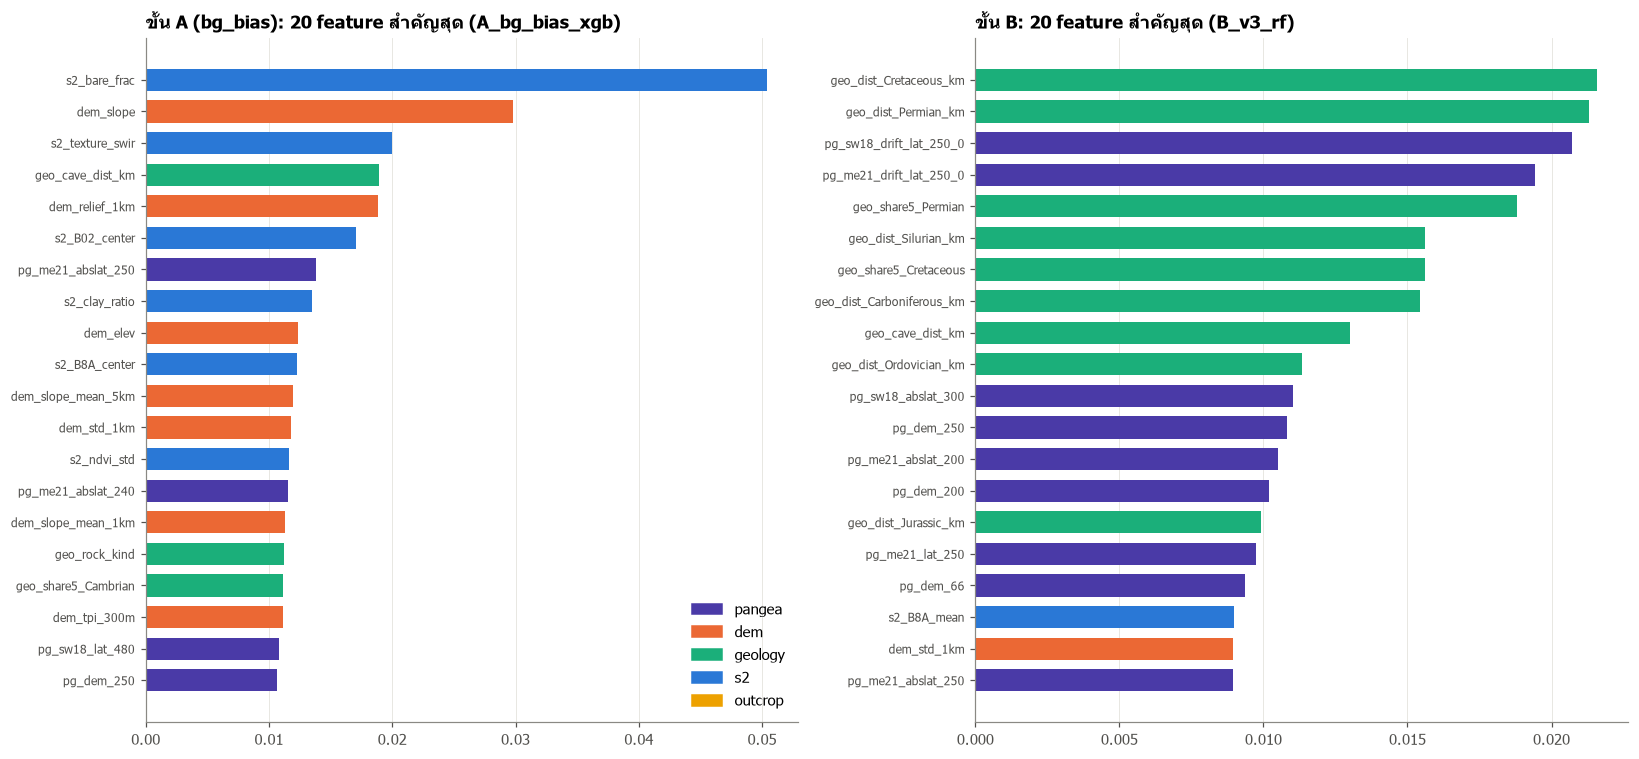

In [15]:
# feature importance ของโมเดลตาราง (ถ้าเป็นต้นไม้)
def importance(path, k=20):
    b = joblib_load(path)
    m = b["model"]
    ms = m if isinstance(m, list) else [m]
    imp = np.mean([mm.feature_importances_ for mm in ms if mm is not None and hasattr(mm, "feature_importances_")], axis=0)
    return pd.Series(imp, index=b["pre"].num_cols + b["pre"].cat_cols).sort_values(ascending=False).head(k)


from joblib import load as joblib_load

grp_color = {"pg_": "#4a3aa7", "dem": "#eb6834", "geo": "#1baf7a", "s2_": "#2a78d6", "oc_": "#eda100"}
paths = [FINAL / meta["stage_A"]["bg_bias"]["tabular"], tabB_path]
fig, axes = plt.subplots(1, 2, figsize=(15, 7))
for ax, path, title in zip(axes, paths, ["ขั้น A (bg_bias)", "ขั้น B"]):
    if path.suffix != ".joblib":
        ax.set_visible(False)
        continue
    imp = importance(path)[::-1]
    ax.barh(imp.index, imp.values, color=[grp_color.get(c[:3], MUTED) for c in imp.index], height=0.7)
    ax.set_title(f"{title}: 20 feature สำคัญสุด ({path.stem})")
    ax.tick_params(axis="y", labelsize=8)
    ax.grid(axis="y", visible=False)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in grp_color.values()]
axes[0].legend(handles, ["pangea", "dem", "geology", "s2", "outcrop"], frameon=False, loc="lower right")
plt.tight_layout()

## สรุป

**ขั้น A — โอกาสพบซาก** (AUC, `spatial_block` = ป้อนพิกัดในพื้นที่ที่ไม่เคยเห็น)

| | `bg_bias` | `bg_uniform` |
|---|---|---|
| XGBoost (โมเดลตัวจริง) | **0.887** | **0.930** |
| LightGBM / RF / MLP | 0.884 / 0.864 / 0.846 | 0.928 / 0.917 / 0.910 |
| CNN (ภาพ Sentinel-2 อย่างเดียว) | 0.792 | 0.818 |
| fusion (LightGBM + CNN) | 0.882 | 0.910 |
| kNN บนพิกัดอย่างเดียว | 0.566 | 0.780 |
| PBDB (ทดสอบอิสระ, XGBoost): AUC / KS | 0.797 / 0.458 | 0.815 / 0.513 |

- **`random` CV สูงเกินจริงจากการจำตำแหน่ง**: kNN บนพิกัดได้ 0.82 ใน `random` แต่เหลือ 0.57 ใน `spatial_block` (`bg_bias`) — ใช้ `spatial_block` เป็นตัวเลขหลัก
- **`bg_uniform` สูงกว่าเพราะเรียนรู้ "ทธ. สำรวจที่ไหน" ส่วนหนึ่ง** (พิกัดอย่างเดียวได้ 0.78) — `bg_bias` ตัดผลนี้ออก ตัวเลขซื่อตรงกว่า
  จึงใช้ `bg_bias` เป็นค่าเริ่มต้นและแสดง `bg_uniform` คู่กัน
- **ที่มาของความแม่น** (LightGBM, `bg_bias`): ภูมิประเทศ + ธรณีวิทยา 0.867 → + Sentinel-2 + พันเจีย 0.884;
  พันเจียอย่างเดียว 0.581 (ในไทย ละติจูดโบราณแทบเป็นฟังก์ชันของตำแหน่งปัจจุบัน จึงทำงานเหมือนพิกัด); ตัดละติจูดโบราณทั้งหมดได้ 0.882
- **ตรวจ data leak**: ตัดละติจูด ณ 0 ล้านปี / ข้อมูลการถ่ายภาพแล้ว; `s2_bare_frac` (feature สำคัญอันดับ 1) อาจสะท้อนการขุดค้นเอง —
  ตัดทิ้งได้ 0.882, ตัดทั้งกลุ่มพื้นโล่ง (bare, NDVI, BSI, ความสว่าง) ได้ 0.885 → โมเดลไม่ได้พึ่ง feature นี้ ความสำคัญแค่กระจายในกลุ่มที่สัมพันธ์กัน
- **CNN ไม่ช่วยเมื่อเฉลี่ยรวม**: fusion แย่กว่าโมเดลตารางทั้ง CV และ PBDB (0.797 → 0.729) → **ใช้โมเดลตารางอย่างเดียว** (`deploy.use_cnn = false`);
  CNN ยังใช้เป็น embedding ในงานที่ 1
- PBDB ใกล้แหล่ง ทธ. หลายแห่ง (พิกัดอย่างเดียวได้ 0.77) จึงเป็นการทดสอบอิสระแค่บางส่วน — notebook 10b เทียบ PBDB กับกริดทั้งประเทศอีกครั้ง

**ขั้น B — ประเภทซาก** (16 ประเภท, `spatial_block`): RF macro AUC **0.758**, top-3 hit 0.776 (prior 0.528); PBDB macro AUC 0.776, top-3 0.651
- **แก้ label หลังตรวจทาน** (2 รอบ): คำของประเภทซากที่เป็นชื่อสถานที่ทำให้ติดประเภทผิด — รอบแรก 14 จาก 25 แหล่ง "สัตว์เลี้ยงลูกด้วยนม"
  (เขาประทับช้าง, ถ้ำค้างคาว, "กวางสีคอนชา" ฯลฯ), รอบสองอีก 2 แหล่ง (ภูเต่า → เต่า, เขาปลาร้า → ปลา) — ตัดชื่อสถานที่ก่อนจับคำ
  และลดเกณฑ์เป็น ≥ 10 แหล่ง (สัตว์เลี้ยงลูกด้วยนม 11, แกรปโตไลต์ 12)
- ทายได้ดี (RF, ตารางรายประเภทด้านบน): แกรปโตไลต์ 0.951, ไดโนเสาร์ 0.950, ปลา 0.891, สัตว์เลื้อยคลานอื่น 0.888, สัตว์เลี้ยงลูกด้วยนม 0.878,
  ไทรโลไบต์ 0.861, ฟอแรม/ฟิวซูลินิด 0.826
- ทายไม่ได้: หอยสองฝา 0.497, พืช 0.603, ร่องรอย 0.606 (พบได้ในหินหลายยุค/หลายสภาพแวดล้อม)
- feature เด่น: ระยะถึงหินยุคเพอร์เมียน/ครีเทเชียส และ**การเคลื่อนของแผ่นเปลือกโลก 250 ล้านปี → ปัจจุบัน** (แยก Sibumasu / Indochina);
  พันเจียอย่างเดียวได้ 0.718 ใกล้ภูมิประเทศ + ธรณีวิทยา (0.735) — มีประโยชน์กับ "ประเภท" มากกว่า "โอกาสพบ"
- ตัด `s2_bare_frac` / กลุ่มพื้นโล่ง / ละติจูดโบราณ: 0.741–0.744 (เท่าเดิม)
- **ทดลอง label จากตัวอย่างที่เชื่อมแบบเข้มงวด** (หัวข้อ 4b; บางคู่แหล่ง–ประเภทผิดชัด เช่น ลิง *Macaca* ติดแหล่งแบรคิโอพอดในกระบี่):
  ตัวอย่างต้องเชื่อมระดับตำแหน่ง/ตำบล + high → PBDB macro AUC 0.787 แต่ top-3 0.635; คำในชื่อเท่านั้น → 0.791 / 0.639
  เทียบกับปัจจุบัน 0.776 / 0.651 — ส่วนต่างทุกค่าคร่อม 0 (bootstrap) → **ตกลงคง label แบบปัจจุบัน**

**ขอบเขตที่โมเดลใช้ได้ (AOA)**: เกณฑ์ DI 0.493 (`bg_bias`), 0.421 (`bg_uniform`), 0.578 (ขั้น B); จุด train ที่ตกนอกขอบเขตเมื่อทำ CV 2.7–3.5%
และ PBDB อยู่ในขอบเขต 92% / 95% / 87% — ขั้น B แคบกว่าเพราะ train ด้วยแหล่ง 490 แห่งเท่านั้น

**โมเดลตัวจริง** (`models/task2/final/`): `A_bg_bias_xgb.joblib`, `A_bg_uniform_xgb.joblib`, `B_v3_rf.joblib`, `aoa_*.joblib`
(+ CNN ตัวจริงสำหรับ embedding) และ `final_meta.json` (feature, คลาส, คะแนน CV, การตั้งค่า `deploy`, ไฟล์ AOA)